<a href="https://colab.research.google.com/github/WellingtonRoque/MineracaoDados/blob/main/atividades/aula10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

📊 Aula 10 — Visualização de Dados

Transformando dados em informações para tomada de decisão

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

print("Ambiente preparado!")

Ambiente preparado!


📥 4. Criando a base de trabalho

Vamos gerar uma base simulada de leituras industriais.

In [2]:

n = 300

df = pd.DataFrame({
    "motor": np.random.choice(["M001", "M002", "M003", "M004", "M005"], n),
    "temperatura": np.random.normal(65, 8, n),
    "vibracao": np.random.normal(2.2, 0.7, n),
    "corrente": np.random.normal(13, 2, n),
    "tensao": np.random.normal(380, 4, n),
    "rpm": np.random.normal(1740, 15, n)
})

df.head()

,motor,temperatura,vibracao,corrente,tensao,rpm
0,M004,63.979162,1.590127,12.379309,377.934204,1739.724765
1,M005,67.732726,2.041275,13.231370,380.176975,1759.676759
2,M003,81.951090,1.660239,10.498007,375.050633,1725.769173
3,M005,77.372294,2.603322,18.211955,382.516996,1707.572318
4,M005,57.403848,3.032720,11.534120,380.763751,1745.496857


📊 6. Gráfico de barras

Queremos comparar a temperatura média dos motores.

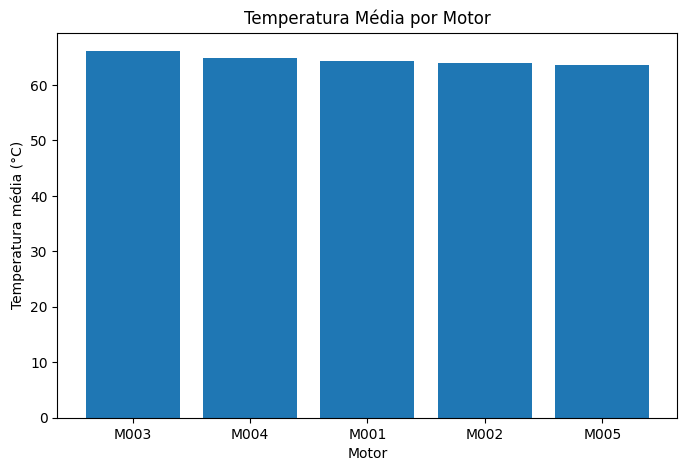

In [3]:
media_motor = (
    df.groupby("motor")["temperatura"]
      .mean()
      .sort_values(ascending=False)
)

plt.figure(figsize=(8, 5))
plt.bar(media_motor.index, media_motor.values)
plt.title("Temperatura Média por Motor")
plt.xlabel("Motor")
plt.ylabel("Temperatura média (°C)")
plt.show()

📈 7. Gráfico de linha

O gráfico de linha é adequado para observar evolução ao longo do tempo.

Vamos criar uma sequência temporal para um motor.

In [4]:
datas = pd.date_range(
    start="2026-03-01 08:00",
    periods=48,
    freq="h"
)

temperaturas = 65 + np.linspace(0, 18, 48) + np.random.normal(0, 2, 48)

df_tempo = pd.DataFrame({
    "data_hora": datas,
    "temperatura": temperaturas
})

df_tempo.head()

,data_hora,temperatura
0,2026-03-01 08:00:00,66.591406
1,2026-03-01 09:00:00,66.620307
2,2026-03-01 10:00:00,64.811953
3,2026-03-01 11:00:00,67.481837
4,2026-03-01 12:00:00,65.896768


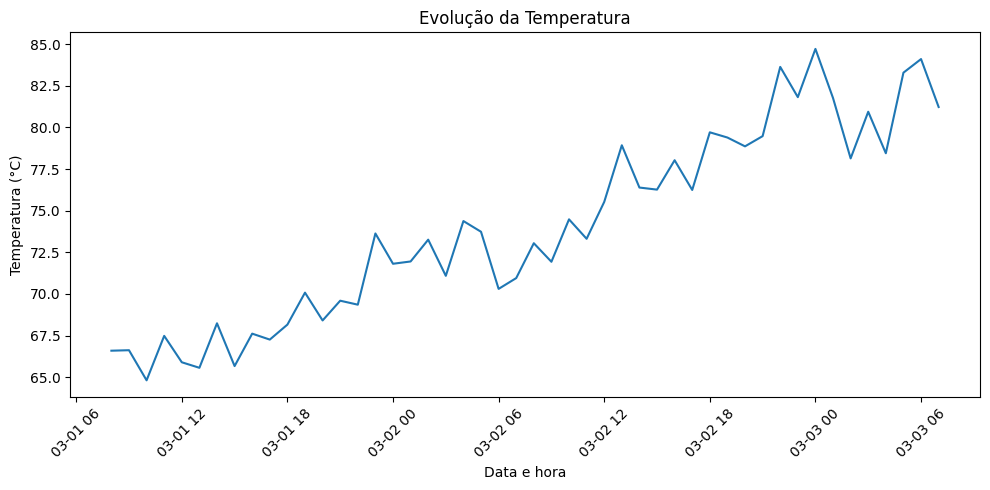

In [5]:
plt.figure(figsize=(10, 5))
plt.plot(df_tempo["data_hora"], df_tempo["temperatura"])
plt.title("Evolução da Temperatura")
plt.xlabel("Data e hora")
plt.ylabel("Temperatura (°C)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

📉 8. Criando uma situação de alerta

Vamos destacar mentalmente a ideia de limite.

Suponha que a equipe de manutenção considere:

Temperatura < 80 °C → operação normal
Temperatura ≥ 80 °C → atenção
Podemos visualizar esse limite junto com os dados.

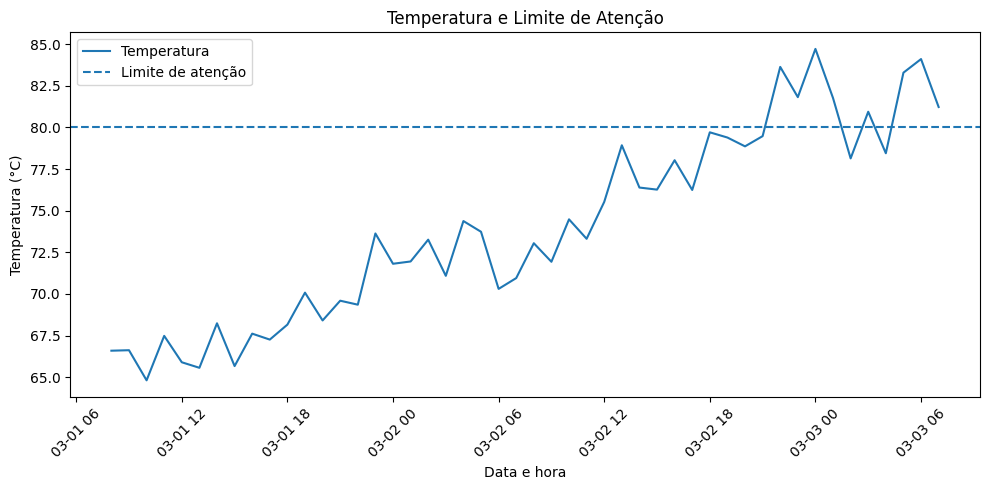

In [6]:

plt.figure(figsize=(10, 5))
plt.plot(df_tempo["data_hora"], df_tempo["temperatura"], label="Temperatura")
plt.axhline(80, linestyle="--", label="Limite de atenção")
plt.title("Temperatura e Limite de Atenção")
plt.xlabel("Data e hora")
plt.ylabel("Temperatura (°C)")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

📦 9. Boxplot

Vamos comparar a distribuição de temperatura entre os motores.

/tmp/ipykernel_1577/2992819547.py:7: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(dados_boxplot, labels=sorted(df["motor"].unique()))


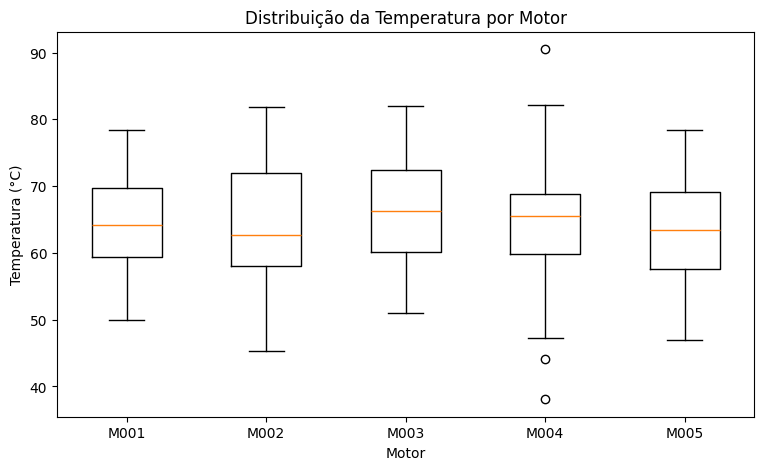

In [7]:

dados_boxplot = [
    df.loc[df["motor"] == motor, "temperatura"]
    for motor in sorted(df["motor"].unique())
]

plt.figure(figsize=(9, 5))
plt.boxplot(dados_boxplot, labels=sorted(df["motor"].unique()))
plt.title("Distribuição da Temperatura por Motor")
plt.xlabel("Motor")
plt.ylabel("Temperatura (°C)")
plt.show()

📊 10. Histograma

Agora vamos analisar a distribuição da vibração.

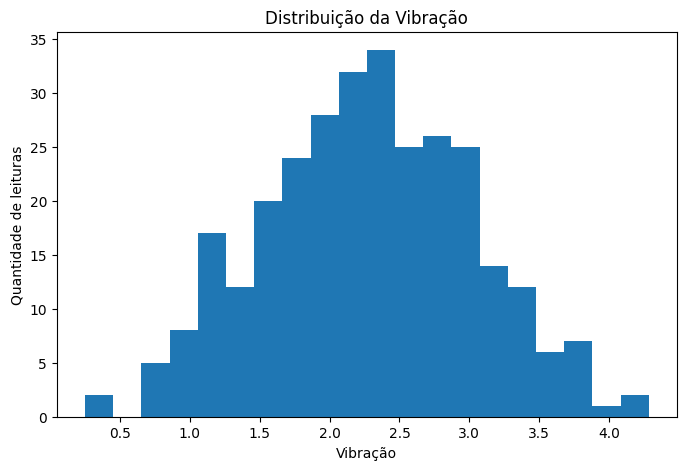

In [8]:
plt.figure(figsize=(8, 5))
plt.hist(df["vibracao"], bins=20)
plt.title("Distribuição da Vibração")
plt.xlabel("Vibração")
plt.ylabel("Quantidade de leituras")
plt.show()

🔵 11. Gráfico de dispersão

Agora queremos investigar uma relação:

Temperatura × Vibração

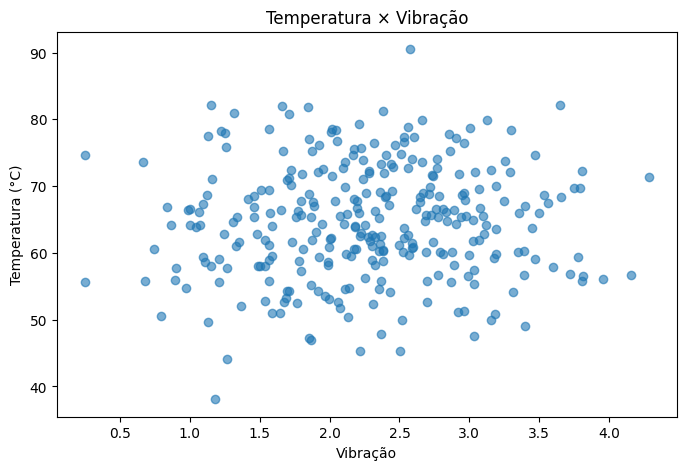

In [9]:

plt.figure(figsize=(8, 5))
plt.scatter(
    df["vibracao"],
    df["temperatura"],
    alpha=0.6
)
plt.title("Temperatura × Vibração")
plt.xlabel("Vibração")
plt.ylabel("Temperatura (°C)")
plt.show()

🎯 12. Colorindo categorias

Podemos utilizar uma variável categórica para facilitar a comparação.

Vamos criar um indicador simples.

In [10]:
df["situacao"] = np.where(
    (df["temperatura"] >= 80) | (df["vibracao"] >= 3),
    "Atenção",
    "Normal"
)

df["situacao"].value_counts()

,count
situacao,
Normal,242
Atenção,58



Agora vamos separar visualmente as situações.


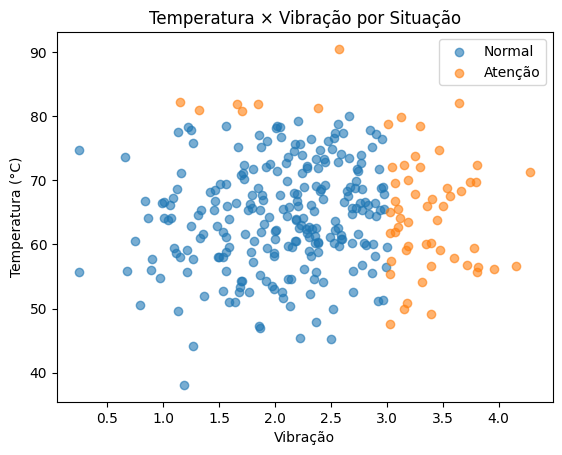

In [11]:

for situacao in df["situacao"].unique():
    dados = df[df["situacao"] == situacao]
    plt.scatter(
        dados["vibracao"],
        dados["temperatura"],
        alpha=0.6,
        label=situacao
    )

plt.title("Temperatura × Vibração por Situação")
plt.xlabel("Vibração")
plt.ylabel("Temperatura (°C)")
plt.legend()
plt.show()

📊 13. Comparando corrente por motor

Vamos utilizar barras para comparar outra variável.

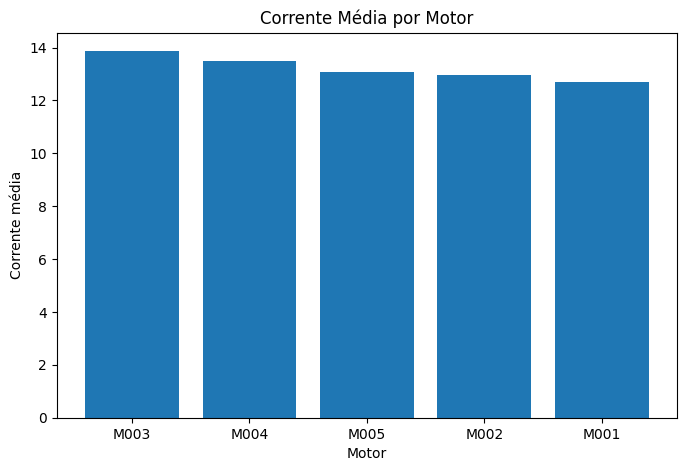

In [12]:
media_corrente = (
    df.groupby("motor")["corrente"]
      .mean()
      .sort_values(ascending=False)
)

plt.figure(figsize=(8, 5))
plt.bar(media_corrente.index, media_corrente.values)
plt.title("Corrente Média por Motor")
plt.xlabel("Motor")
plt.ylabel("Corrente média")
plt.show()

🧩 14. Criando um pequeno painel exploratório

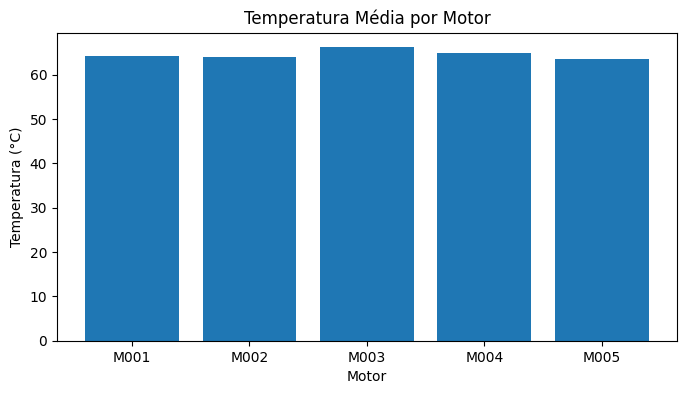

In [13]:
# Gráfico 1 — Temperatura média por motor

media_temp = df.groupby("motor")["temperatura"].mean()

plt.figure(figsize=(8, 4))
plt.bar(media_temp.index, media_temp.values)
plt.title("Temperatura Média por Motor")
plt.xlabel("Motor")
plt.ylabel("Temperatura (°C)")
plt.show()

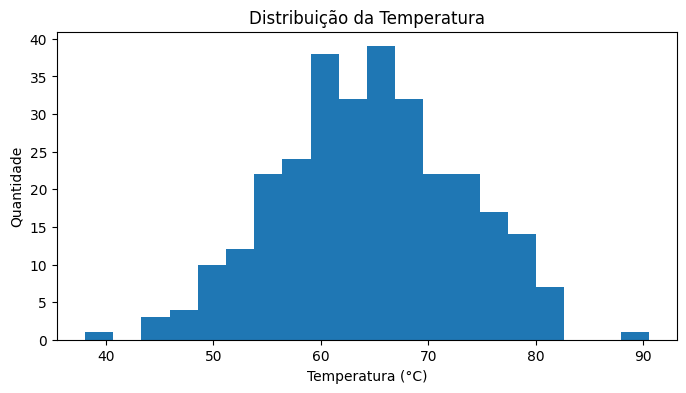

In [14]:
# Gráfico 2 — Distribuição da temperatura

plt.figure(figsize=(8, 4))
plt.hist(df["temperatura"], bins=20)
plt.title("Distribuição da Temperatura")
plt.xlabel("Temperatura (°C)")
plt.ylabel("Quantidade")
plt.show()

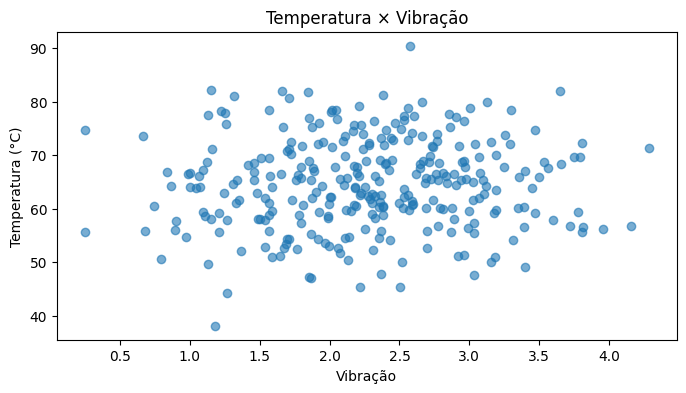

In [15]:
# Gráfico 3 — Temperatura x Vibração

plt.figure(figsize=(8, 4))
plt.scatter(df["vibracao"], df["temperatura"], alpha=0.6)
plt.title("Temperatura × Vibração")
plt.xlabel("Vibração")
plt.ylabel("Temperatura (°C)")
plt.show()

/tmp/ipykernel_1577/3844126538.py:9: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(dados_boxplot, labels=sorted(df["motor"].unique()))


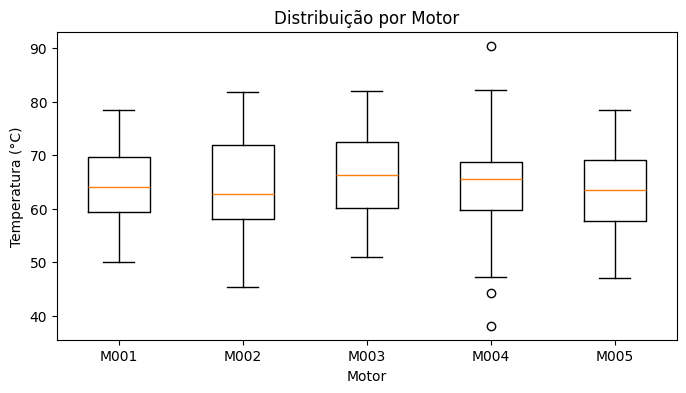

In [16]:
# Gráfico 4 — Boxplot

dados_boxplot = [
    df.loc[df["motor"] == motor, "temperatura"]
    for motor in sorted(df["motor"].unique())
]

plt.figure(figsize=(8, 4))
plt.boxplot(dados_boxplot, labels=sorted(df["motor"].unique()))
plt.title("Distribuição por Motor")
plt.xlabel("Motor")
plt.ylabel("Temperatura (°C)")
plt.show()